# Faktor-Faktor yang Berkaitan dengan Kepuasan Hidup Komuter

Notebook ini menganalisis faktor-faktor yang **berasosiasi** dengan kepuasan hidup komuter menggunakan `data_commuter Raw.csv` dan kamus `Data_Kuesioner_Komuter.xlsx`. Berbeda dari analisis sebelumnya, fokusnya adalah mengidentifikasi faktor perjalanan, stres/waktu, kondisi ekonomi/perumahan, rumah tangga, dan demografi yang paling erat hubungannya dengan kepuasan hidup.

**Pertanyaan analisis**
1. Faktor pengalaman perjalanan dan tekanan komuter mana yang paling kuat terkait dengan kepuasan hidup? Apakah pola bivariat tetap terlihat saat beberapa faktor dipertimbangkan bersama?
2. Apakah keterjangkauan/kelayakan rumah dan persepsi maupun nominal pendapatan terkait dengan kepuasan hidup? Apakah pendapatan tinggi tampak mengimbangi tekanan perjalanan?
3. Bagaimana variasi kepuasan menurut gender, usia, status pernikahan, pekerjaan, dan tanggungan rumah tangga?
4. Apakah segmentasi K-Means berdasarkan pengalaman perjalanan/tekanan membedakan tingkat kepuasan hidup?

Notebook mencakup pembersihan, EDA, visualisasi, K-Means K=3 (elbow K=2?10 dan Davies?Bouldin Index), model prediktif eksploratif dan kesimpulan yang dibuat dari hasil perhitungan, bukan asumsi.

## Catatan metodologi dan definisi target

Kamus menjelaskan `F.6` sebagai pernyataan negatif: **kepuasan hidup berkurang akibat menjadi komuter**. Karena itu target utama dibuat `Kepuasan_F6` = `6 - F.6`, sehingga skor lebih besar mengindikasikan kepuasan lebih baik. Kolom kategori `Kepuasan Hidup` dianalisis terpisah karena kamus yang tersedia tidak menjelaskan bagaimana kategori tersebut dibentuk atau dipetakan ke F.6.

Analisis hubungan/pemodelan adalah eksplorasi asosiasi, bukan bukti faktor kausal. Respons Likert 1?5 diperlakukan sebagai numerik untuk ringkasan, korelasi, regresi, dan jarak K-Means (sebuah pendekatan praktis dengan keterbatasan). Model prediktif memasukkan F.1?F.5, F.7?F.8 sebagai jawaban survei yang berdekatan dengan F.6; hubungan dapat dipengaruhi kesamaan konstruk dan metode pengukuran. Nilai `D.5` adalah konversi USD dari `D.4`, maka D.5 tidak dimasukkan sebagai prediktor bersamaan. ID dan kategori kepuasan juga tidak menjadi prediktor.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import KFold, cross_val_score, train_test_split
from sklearn.inspection import permutation_importance
from sklearn.metrics import davies_bouldin_score, mean_absolute_error, mean_squared_error, r2_score

SEED = 42
CSV_PATH = Path("data_commuter Raw.csv")
if not CSV_PATH.exists():
    raise FileNotFoundError(f"File input tidak ditemukan: {CSV_PATH.resolve()}")
pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 180)
sns.set_theme(style="whitegrid", palette="Set2")


In [2]:
raw = pd.read_csv(CSV_PATH)
print(f"Ukuran dataset: {raw.shape[0]} responden x {raw.shape[1]} kolom")
display(raw.head())
print("\nTipe data:")
display(raw.dtypes.rename("dtype").to_frame())


Ukuran dataset: 384 responden x 30 kolom
   No. Responden  A.1  A.2  A.3  A.4  A.5  A.6  B.1  B.2  C.1  C.2  C.3   C.4  D.1  D.2  D.3      D.4     D.5  E.1  E.2  E.3  F.1  F.2  F.3  F.4  F.5  F.6  F.7  F.8     Kepuasan Hidup
0              1    1   30    1    3    1    1    4    4    1    1    2  2.00    4    4    4  2500000  178.57    4    4    5    4    3    4    4    4    3    3    3  Sangat Tidak Puas
1              2    1   40    1    3    1    5    4    5    2    2    4  2.00    4    4    5  1200000   85.71    4    5    4    4    3    4    4    5    4    4    5  Sangat Tidak Puas
2              3    1   38    1    3    1    5    4    4    1    2    3  3.00    3    4    5  1600000  114.29    4    4    5    5    4    4    3    3    3    3    4  Sangat Tidak Puas
3              4    1   27    2    3    1    5    5    4    2    2    4  2.00    4    4    5  1500000  107.14    4    5    4    4    5    5    4    3    4    5    4  Sangat Tidak Puas
4              5    2   28    2    3   

## Kamus variabel yang digunakan

Deskripsi berikut berasal dari workbook kuesioner. Beberapa kolom memiliki kode pilihan angka; kode diperlakukan kategorikal dan tidak disimpulkan sebagai urutan kecuali pertanyaannya memang berskala Likert. Rentang pilihan kategori A.4?A.6/B.1?B.2/D.1?D.3 tersedia di workbook dan dipetakan di tabel ini.

In [3]:
var_guide = pd.DataFrame([
    ("A.1", "Jenis kelamin", "1 laki-laki; 2 perempuan", "Kategori"),
    ("A.2", "Usia", "Rasio, tahun", "Demografi"),
    ("A.3", "Status pernikahan", "1 menikah; 2 single; 3 widower; 4 widow", "Kategori"),
    ("A.4", "Latar pendidikan", "1 SD; 2 SMP; 3 SMA; 4 diploma; 5 undergraduate; 6 graduate", "Kategori"),
    ("A.5", "Agama", "Kategori kode; kategori sangat jarang tidak ditafsirkan", "Kategori"),
    ("A.6", "Pekerjaan", "1 PNS; 2 polisi/militer; 3 swasta; 4 wiraswasta; 5 lainnya", "Kategori"),
    ("B.1", "Keterjangkauan biaya perumahan", "Likert 1-5; tinggi = lebih terjangkau", "Perumahan"),
    ("B.2", "Kelayakan rumah", "Likert 1-5; tinggi = lebih layak", "Perumahan"),
    ("C.1-C.4", "Komposisi keluarga dan rasio ketergantungan", "Jumlah anggota bekerja/tidak bekerja/anggota keluarga; rasio ketergantungan", "Rumah tangga"),
    ("D.1", "Pendapatan sebagai komuter lebih besar", "Likert 1-5; persetujuan", "Ekonomi"),
    ("D.2", "Penghasilan sebagai komuter itu layak", "Likert 1-5; persetujuan", "Ekonomi"),
    ("D.3", "Kepatuhan/kesesuaian waktu kerja terhadap pendapatan", "Likert 1-5; tinggi = lebih sesuai", "Ekonomi"),
    ("D.4/D.5", "Pendapatan bulanan", "IDR / USD; satu nilai dalam dua mata uang", "Ekonomi"),
    ("E.1", "Kemudahan moda transportasi", "Likert 1-5; tinggi = lebih mudah", "Perjalanan"),
    ("E.2", "Kenyamanan perjalanan", "Likert 1-5; tinggi = lebih nyaman", "Perjalanan"),
    ("E.3", "Keadilan waktu tempuh", "Likert 1-5; tinggi = lebih adil", "Perjalanan"),
    ("F.1-F.5, F.7-F.8", "Persepsi dampak perjalanan/stres/waktu", "Pernyataan masalah; umumnya tinggi = dampak lebih berat", "Psikologis"),
    ("F.6", "Kepuasan hidup berkurang", "Pernyataan negatif; target dibalik agar tinggi = lebih puas", "Target"),
    ("Kepuasan Hidup", "Kategori kepuasan hidup", "Kategori dari dataset; pemetaan ke F.6 tidak diketahui", "Target kategorikal"),
], columns=["Kode", "Deskripsi", "Skala/kode", "Domain"])
display(var_guide)


                Kode                                             Deskripsi                                                                   Skala/kode              Domain
0                A.1                                         Jenis kelamin                                                     1 laki-laki; 2 perempuan            Kategori
1                A.2                                                  Usia                                                                 Rasio, tahun           Demografi
2                A.3                                     Status pernikahan                                      1 menikah; 2 single; 3 widower; 4 widow            Kategori
3                A.4                                      Latar pendidikan                   1 SD; 2 SMP; 3 SMA; 4 diploma; 5 undergraduate; 6 graduate            Kategori
4                A.5                                                 Agama                      Kategori kode; kategori sangat jarang tidak 

## Pembersihan dan pemeriksaan kualitas data

Pemeriksaan mencakup ID ganda, duplikat baris identik, nilai kosong, rentang Likert, usia dan pendapatan. Nilai nominal seperti kode pendidikan/agama/pekerjaan dipertahankan, tidak dibuang atau dianggap kontinu. Bila ada anomali yang tidak dapat ditangani dengan aman, notebook menghentikan proses dengan pesan yang eksplisit.

In [4]:
likert_cols = ["B.1", "B.2", "D.1", "D.2", "D.3", "E.1", "E.2", "E.3", *[f"F.{i}" for i in range(1, 9)]]
required = ["No. Responden", "A.1", "A.2", "A.3", "A.4", "A.5", "A.6", "B.1", "B.2", "C.1", "C.2", "C.3", "C.4", "D.1", "D.2", "D.3", "D.4", "D.5", *[f"E.{i}" for i in range(1,4)], *[f"F.{i}" for i in range(1,9)], "Kepuasan Hidup"]
missing_cols = sorted(set(required)-set(raw.columns))
if missing_cols:
    raise ValueError(f"Kolom wajib tidak ditemukan: {missing_cols}")
df = raw.copy()
for col in required:
    if col != "Kepuasan Hidup":
        df[col] = pd.to_numeric(df[col], errors="coerce")
start_n = len(df)
duplicate_rows = int(df.duplicated().sum())
if duplicate_rows:
    df = df.drop_duplicates().copy()
duplicate_ids = int(df["No. Responden"].duplicated().sum())
if duplicate_ids:
    raise ValueError(f"ID responden duplikat sebanyak {duplicate_ids}; perlu tinjauan manual.")
missing_counts = df[required].isna().sum()
if missing_counts.any():
    raise ValueError("Nilai kosong/konversi gagal: " + missing_counts[missing_counts.gt(0)].to_dict().__str__())
invalid = {c: int((~df[c].between(1,5)).sum()) for c in likert_cols}
invalid = {c:n for c,n in invalid.items() if n}
if invalid:
    raise ValueError(f"Jawaban di luar rentang Likert 1-5: {invalid}")
if (df[["A.2", "D.4", "D.5"]] < 0).any().any():
    raise ValueError("Usia atau pendapatan negatif ditemukan.")
if not df["A.2"].between(18, 100).all():
    raise ValueError("Ditemukan usia di luar batas pemeriksaan 18-100 tahun.")

df["Gender"] = df["A.1"].map({1:"Laki-laki",2:"Perempuan"}).fillna("Kode lain/perlu cek")
df["Status"] = df["A.3"].map({1:"Menikah",2:"Single",3:"Duda",4:"Janda"}).fillna("Kode lain/perlu cek")
df["Pekerjaan"] = df["A.6"].map({1:"PNS",2:"Polisi/Militer",3:"Pegawai swasta",4:"Wiraswasta",5:"Lainnya"}).fillna("Kode lain/perlu cek")
df["Kepuasan_F6"] = 6 - df["F.6"]
df["Kepuasan Hidup"] = df["Kepuasan Hidup"].astype("string").str.strip()
quality = pd.DataFrame({"Pemeriksaan":["Baris awal","Baris setelah drop duplikat persis","Duplikat baris yang dihapus","ID duplikat","Kolom wajib missing","Respons Likert valid"],"Hasil":[start_n,len(df),duplicate_rows,duplicate_ids,int(missing_counts.gt(0).sum()),not bool(invalid)]})
display(quality)
print("Label kategori Kepuasan Hidup:", sorted(df["Kepuasan Hidup"].dropna().unique().tolist()))


                          Pemeriksaan Hasil
0                          Baris awal   384
1  Baris setelah drop duplikat persis   384
2         Duplikat baris yang dihapus     0
3                         ID duplikat     0
4                 Kolom wajib missing     0
5                Respons Likert valid  True
Label kategori Kepuasan Hidup: ['Biasa', 'Sangat Puas', 'Sangat Tidak Puas']


In [5]:
clean_path = Path("data_commuter_clean_faktor_kepuasan.csv")
df.to_csv(clean_path, index=False, encoding="utf-8-sig")
print(f"Dataset hasil pembersihan disimpan ke {clean_path.resolve()}")


Dataset hasil pembersihan disimpan ke D:\Document\Excel\Dataset Komuter\data_commuter_clean_faktor_kepuasan.csv


## EDA ? demografi, ekonomi, rumah tangga, perjalanan, dan kepuasan

Mulai dari ringkasan angka dan frekuensi sebelum menilai hubungan. Kategori jarang ditampilkan dengan jumlahnya agar tidak memunculkan klaim luas dari sampel yang sangat kecil.

In [6]:
print("Ringkasan variabel numerik:")
display(df.select_dtypes(include="number").describe().T.round(2))
for col in ["Gender", "Status", "Pekerjaan", "A.4", "A.5", "Kepuasan Hidup"]:
    print(f"\nDistribusi {col}:")
    display(df[col].value_counts(dropna=False).rename_axis(col).to_frame("n"))


Ringkasan variabel numerik:
               count        mean         std        min         25%         50%         75%          max
No. Responden  384.0      192.50      111.00       1.00       96.75      192.50      288.25       384.00
A.1            384.0        1.26        0.44       1.00        1.00        1.00        2.00         2.00
A.2            384.0       35.17        9.12      18.00       28.00       35.00       40.00        56.00
A.3            384.0        1.32        0.65       1.00        1.00        1.00        1.00         5.00
A.4            384.0        3.27        1.02       1.00        3.00        3.00        4.00         6.00
A.5            384.0        1.08        0.47       1.00        1.00        1.00        1.00         5.00
A.6            384.0        3.52        1.40       1.00        3.00        4.00        5.00         5.00
B.1            384.0        3.93        0.68       2.00        4.00        4.00        4.00         5.00
B.2            384.0       

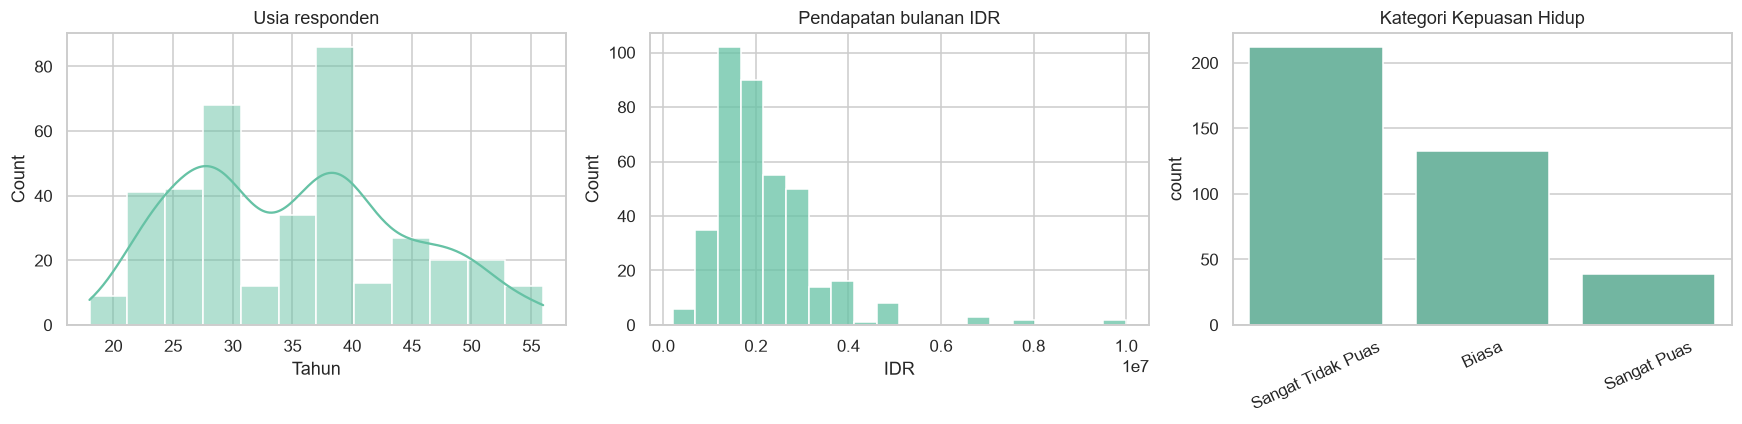

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(16,4))
sns.histplot(df["A.2"], bins=12, kde=True, ax=axes[0]); axes[0].set(title="Usia responden", xlabel="Tahun")
sns.histplot(df["D.4"], bins=20, ax=axes[1]); axes[1].set(title="Pendapatan bulanan IDR", xlabel="IDR")
sns.countplot(data=df, x="Kepuasan Hidup", order=df["Kepuasan Hidup"].value_counts().index, ax=axes[2]); axes[2].tick_params(axis="x",rotation=25); axes[2].set(title="Kategori Kepuasan Hidup",xlabel="")
plt.tight_layout(); plt.show()


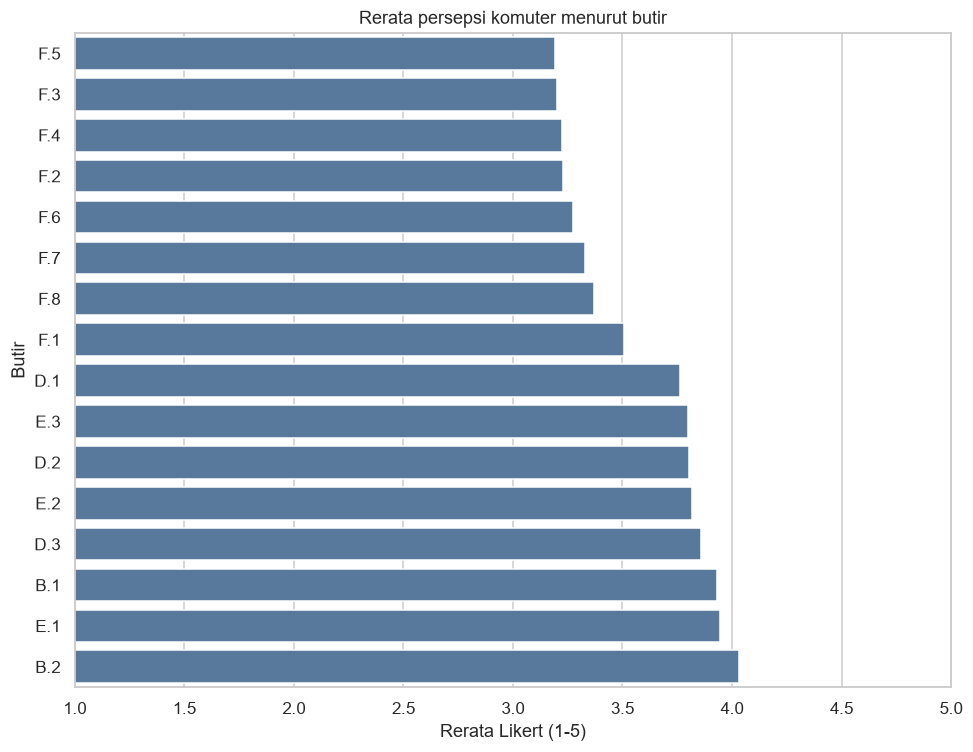

     mean
F.5  3.19
F.3  3.20
F.4  3.22
F.2  3.23
F.6  3.27
F.7  3.33
F.8  3.37
F.1  3.51
D.1  3.76
E.3  3.80
D.2  3.80
E.2  3.82
D.3  3.86
B.1  3.93
E.1  3.95
B.2  4.03


In [8]:
items = ["B.1","B.2","D.1","D.2","D.3","E.1","E.2","E.3",*[f"F.{i}" for i in range(1,9)]]
item_means = df[items].mean().sort_values()
plt.figure(figsize=(9,7)); sns.barplot(x=item_means.values,y=item_means.index,color="#4C78A8"); plt.xlim(1,5); plt.xlabel("Rerata Likert (1-5)"); plt.ylabel("Butir"); plt.title("Rerata persepsi komuter menurut butir"); plt.tight_layout(); plt.show()
display(item_means.rename("mean").to_frame().round(2))


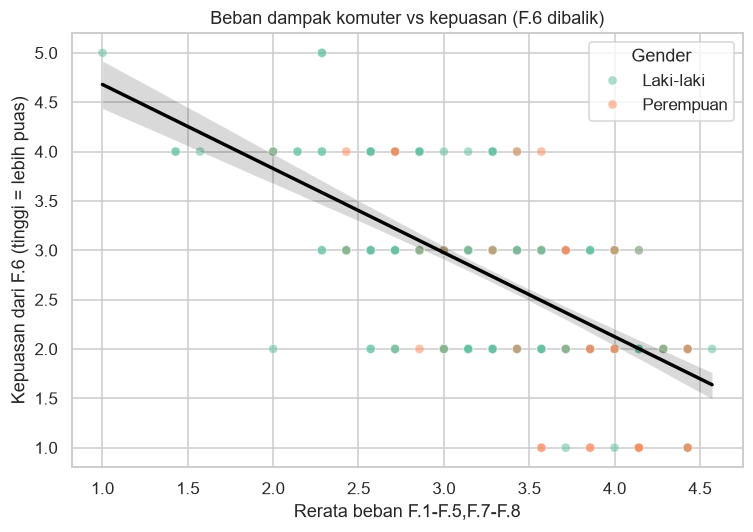

In [9]:
df["F_beban_waktu_stres"] = df[["F.1","F.2","F.3","F.4","F.5","F.7","F.8"]].mean(axis=1)
df["E_perjalanan"] = df[["E.1","E.2","E.3"]].mean(axis=1)
plt.figure(figsize=(7,5)); sns.scatterplot(data=df,x="F_beban_waktu_stres",y="Kepuasan_F6",hue="Gender",alpha=.55); sns.regplot(data=df,x="F_beban_waktu_stres",y="Kepuasan_F6",scatter=False,color="black"); plt.title("Beban dampak komuter vs kepuasan (F.6 dibalik)"); plt.xlabel("Rerata beban F.1-F.5,F.7-F.8"); plt.ylabel("Kepuasan dari F.6 (tinggi = lebih puas)"); plt.tight_layout(); plt.show()


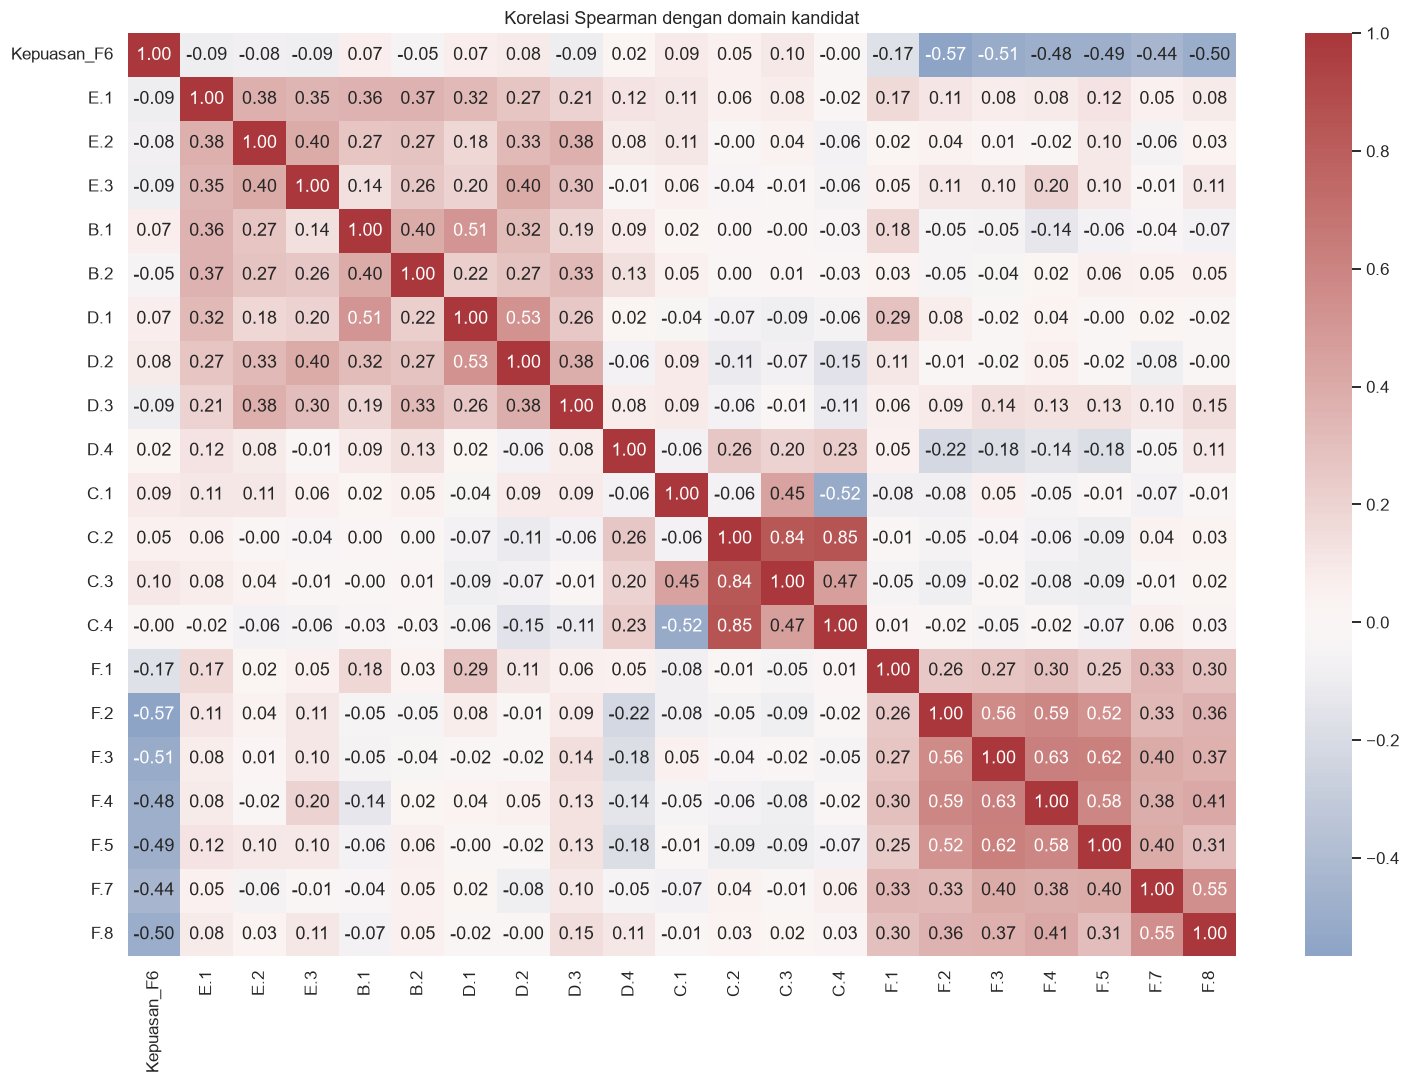

In [10]:
corr_cols = ["Kepuasan_F6","E.1","E.2","E.3","B.1","B.2","D.1","D.2","D.3","D.4","C.1","C.2","C.3","C.4",*[f"F.{i}" for i in [1,2,3,4,5,7,8]]]
plt.figure(figsize=(14,10)); sns.heatmap(df[corr_cols].corr(method="spearman"),cmap="vlag",center=0,annot=True,fmt=".2f"); plt.title("Korelasi Spearman dengan domain kandidat"); plt.tight_layout(); plt.show()


## Pertanyaan 1 ? Faktor perjalanan/stres apa yang paling berkaitan dengan kepuasan?

Pertama bandingkan hubungan bivariat menggunakan Spearman. Lalu model multivariat mengukur prediksi ketika fitur-fitur dipertimbangkan bersama. Skor prediksi dan permutation importance adalah alat eksplorasi, bukan uji signifikansi atau bukti kausal. F.6 dikeluarkan dari prediktor untuk menghindari kebocoran target.

In [11]:
psych_features = ["E.1","E.2","E.3",*[f"F.{i}" for i in [1,2,3,4,5,7,8]]]
psych_corr = df[psych_features].corrwith(df["Kepuasan_F6"],method="spearman").sort_values()
display(psych_corr.rename("Spearman rho vs Kepuasan_F6").to_frame().round(3))
print(f"Korelasi Spearman komposit beban dampak dengan kepuasan: {df['F_beban_waktu_stres'].corr(df['Kepuasan_F6'],method='spearman'):.3f}")


     Spearman rho vs Kepuasan_F6
F.2                       -0.567
F.3                       -0.511
F.8                       -0.502
F.5                       -0.487
F.4                       -0.483
F.7                       -0.436
F.1                       -0.167
E.1                       -0.090
E.3                       -0.087
E.2                       -0.078
Korelasi Spearman komposit beban dampak dengan kepuasan: -0.634


In [12]:
# Bandingkan domain-model dan model penuh dengan 5-fold CV.
econ_features = ["B.1","B.2","D.1","D.2","D.3","D.4","C.1","C.2","C.3","C.4"]
demo_features = ["A.1","A.2","A.3","A.4","A.5","A.6"]
all_features = psych_features + econ_features + demo_features
categorical_features = ["A.1","A.3","A.4","A.5","A.6"]
numeric_features = [c for c in all_features if c not in categorical_features]
X = df[all_features].copy()
X["D.4"] = np.log1p(X["D.4"])
cv = KFold(n_splits=5,shuffle=True,random_state=SEED)
def make_model(features):
    cats=[c for c in categorical_features if c in features]
    nums=[c for c in features if c not in cats]
    prep=ColumnTransformer([("num",StandardScaler(),nums),("cat",OneHotEncoder(handle_unknown="ignore"),cats)])
    return Pipeline([("prep",prep),("model",LinearRegression())])
model_sets={"Perjalanan dan tekanan (E/F)":psych_features,"Ekonomi/perumahan/rumah tangga":econ_features,"Demografi":demo_features,"Semua domain":all_features}
cv_rows=[]
for name,features in model_sets.items():
    scores=cross_val_score(make_model(features),X[features],df["Kepuasan_F6"],cv=cv,scoring="r2")
    cv_rows.append({"Domain model":name,"R2 CV mean":scores.mean(),"R2 CV sd":scores.std()})
cv_results=pd.DataFrame(cv_rows).sort_values("R2 CV mean",ascending=False)
display(cv_results.round(3))


                     Domain model  R2 CV mean  R2 CV sd
3                    Semua domain       0.472     0.070
0    Perjalanan dan tekanan (E/F)       0.467     0.023
2                       Demografi       0.003     0.039
1  Ekonomi/perumahan/rumah tangga      -0.028     0.067


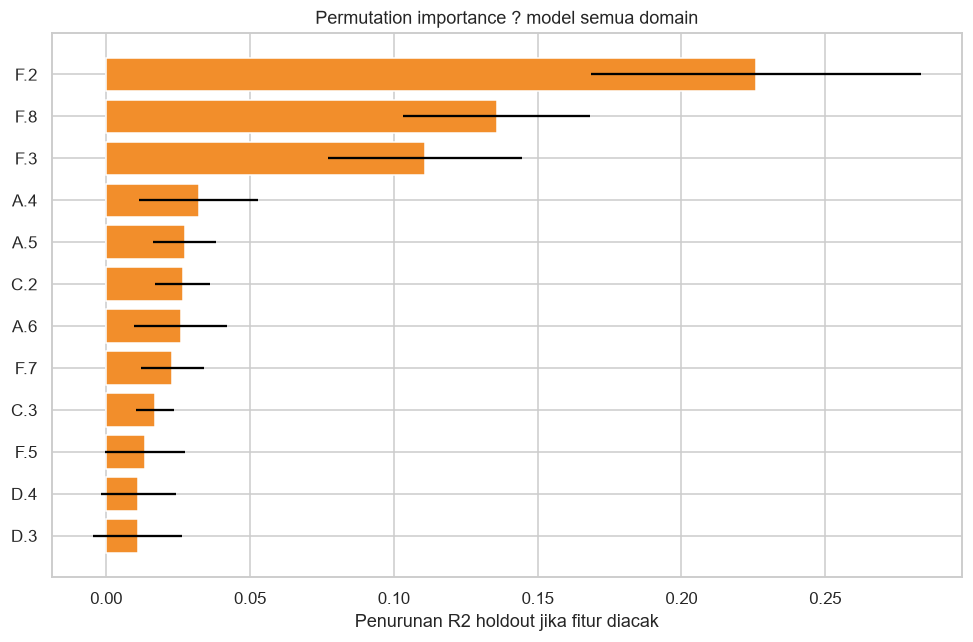

Holdout R2=0.492; MAE=0.466; RMSE=0.575
   Fitur  Penurunan R2 rata-rata      SD
4    F.2                  0.2259  0.0573
9    F.8                  0.1357  0.0323
5    F.3                  0.1108  0.0337
23   A.4                  0.0321  0.0206
24   A.5                  0.0274  0.0109
17   C.2                  0.0267  0.0096
25   A.6                  0.0259  0.0161
8    F.7                  0.0230  0.0111
18   C.3                  0.0169  0.0067
7    F.5                  0.0134  0.0139
15   D.4                  0.0112  0.0131
14   D.3                  0.0109  0.0156
11   B.2                  0.0086  0.0094
12   D.1                  0.0062  0.0073
2    E.3                  0.0047  0.0026


In [13]:
# Holdout permutation importance untuk model penuh; interpretasikan sebagai penurunan R2 saat fitur diacak.
X_train,X_test,y_train,y_test=train_test_split(X[all_features],df["Kepuasan_F6"],test_size=.25,random_state=SEED)
full_model=make_model(all_features)
full_model.fit(X_train,y_train)
y_pred=full_model.predict(X_test)
print(f"Holdout R2={r2_score(y_test,y_pred):.3f}; MAE={mean_absolute_error(y_test,y_pred):.3f}; RMSE={np.sqrt(mean_squared_error(y_test,y_pred)):.3f}")
perm=permutation_importance(full_model,X_test,y_test,n_repeats=40,random_state=SEED,scoring="r2")
importance=pd.DataFrame({"Fitur":all_features,"Penurunan R2 rata-rata":perm.importances_mean,"SD":perm.importances_std}).sort_values("Penurunan R2 rata-rata",ascending=False)
display(importance.head(15).round(4))
plt.figure(figsize=(9,6)); top=importance.head(12).sort_values("Penurunan R2 rata-rata"); plt.barh(top["Fitur"],top["Penurunan R2 rata-rata"],xerr=top["SD"],color="#F28E2B"); plt.xlabel("Penurunan R2 holdout jika fitur diacak"); plt.title("Permutation importance ? model semua domain"); plt.tight_layout(); plt.show()


## Pertanyaan 2 ? Apakah kondisi ekonomi/perumahan berkaitan dengan kepuasan?

Keterjangkauan perumahan (B.1), kelayakan rumah (B.2), persepsi ekonomi (D.1?D.3), serta pendapatan nominal (D.4) dirangkum menurut skornya. Pendapatan dibagi menjadi tercile berdasarkan D.4; `D.5` tidak dipakai untuk model karena hanya menyatakan jumlah alternatif dalam USD. Korelasi dan rerata kelompok tidak menunjukkan bahwa uang secara kausal menutupi dampak perjalanan.

In [14]:
econ_corr_cols=["B.1","B.2","D.1","D.2","D.3","D.4"]
econ_corr=df[econ_corr_cols].corrwith(df["Kepuasan_F6"],method="spearman").sort_values()
display(econ_corr.rename("Spearman rho vs Kepuasan_F6").to_frame().round(3))
try:
    df["Tercile pendapatan"] = pd.qcut(df["D.4"],q=3,labels=["Rendah","Menengah","Tinggi"],duplicates="drop")
except ValueError as exc:
    raise ValueError(f"Tercile pendapatan tidak dapat dibentuk: {exc}")
income_table=df.groupby("Tercile pendapatan",observed=True).agg(n=("No. Responden","size"),median_IDR=("D.4","median"),kepuasan_mean=("Kepuasan_F6","mean"),beban_mean=("F_beban_waktu_stres","mean"),E_mean=("E_perjalanan","mean"))
display(income_table.round(2))


     Spearman rho vs Kepuasan_F6
D.3                       -0.091
B.2                       -0.053
D.4                        0.016
B.1                        0.065
D.1                        0.065
D.2                        0.085
                      n  median_IDR  kepuasan_mean  beban_mean  E_mean
Tercile pendapatan                                                    
Rendah              143   1400000.0           2.69        3.37    3.81
Menengah            140   2000000.0           2.75        3.32    3.88
Tinggi              101   3000000.0           2.74        3.15    3.87


In [15]:
for item in ["B.1","B.2","D.1","D.2","D.3"]:
    print(f"\nRerata target menurut {item}:")
    display(df.groupby(item).agg(n=("No. Responden","size"),kepuasan_mean=("Kepuasan_F6","mean"),kepuasan_median=("Kepuasan_F6","median")).round(2))



Rerata target menurut B.1:
       n  kepuasan_mean  kepuasan_median
B.1                                     
2     10           3.00              3.0
3     72           2.56              3.0
4    237           2.76              3.0
5     65           2.77              3.0

Rerata target menurut B.2:
       n  kepuasan_mean  kepuasan_median
B.2                                     
2      1           4.00              4.0
3     72           2.76              3.0
4    225           2.73              3.0
5     86           2.67              3.0

Rerata target menurut D.1:
       n  kepuasan_mean  kepuasan_median
D.1                                     
2      8           2.75              2.5
3    106           2.62              3.0
4    239           2.78              3.0
5     31           2.65              3.0

Rerata target menurut D.2:
       n  kepuasan_mean  kepuasan_median
D.2                                     
2      6           3.00              3.0
3    101           2.68    

## Pertanyaan 3 ? Variasi demografis dan rumah tangga

Rerata F.6 terbalik dibandingkan menurut gender, status perkawinan, rentang usia, pekerjaan, dan rasio ketergantungan. Kelompok kategori kecil (terutama status non-menikah tertentu) perlu dibaca bersama jumlah responden. Analisis ini deskriptif; model multivariat sebelumnya memasukkan demografi sebagai salah satu domain pengendali eksploratif.

In [16]:
df["Kelompok usia"] = pd.cut(df["A.2"],bins=[17,24,34,44,np.inf],labels=["18-24","25-34","35-44","45+"],include_lowest=True)
for col in ["Gender","Status","Pekerjaan","Kelompok usia"]:
    print(f"\nKepuasan menurut {col}:")
    display(df.groupby(col,observed=False).agg(n=("No. Responden","size"),kepuasan_mean=("Kepuasan_F6","mean"),kepuasan_sd=("Kepuasan_F6","std"),F_beban_mean=("F_beban_waktu_stres","mean")).sort_values("n",ascending=False).round(2))



Kepuasan menurut Gender:
             n  kepuasan_mean  kepuasan_sd  F_beban_mean
Gender                                                  
Laki-laki  285           2.77         0.76          3.24
Perempuan   99           2.61         0.83          3.43

Kepuasan menurut Status:
                       n  kepuasan_mean  kepuasan_sd  F_beban_mean
Status                                                            
Menikah              289           2.76         0.80          3.24
Single                81           2.58         0.72          3.47
Janda                 10           2.80         0.42          3.20
Duda                   3           2.67         0.58          3.71
Kode lain/perlu cek    1           4.00          NaN          2.71

Kepuasan menurut Pekerjaan:
                  n  kepuasan_mean  kepuasan_sd  F_beban_mean
Pekerjaan                                                    
Lainnya         133           2.64         0.68          3.43
Pegawai swasta  110           2.67  

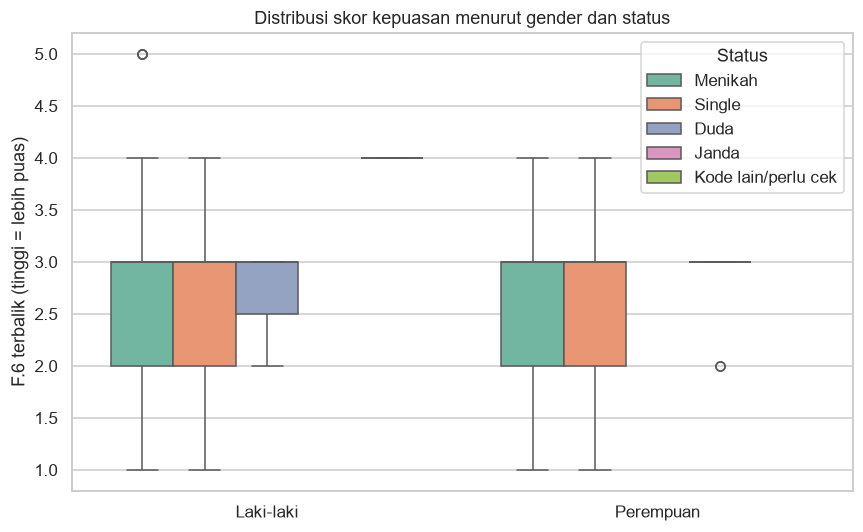

                                 n  kepuasan_mean  beban_F_mean
Gender    Status                                               
Laki-laki Menikah              232           2.81          3.20
Perempuan Menikah               57           2.58          3.41
Laki-laki Single                49           2.57          3.43
Perempuan Single                32           2.59          3.54
          Janda                 10           2.80          3.20
Laki-laki Duda                   3           2.67          3.71
          Kode lain/perlu cek    1           4.00          2.71


In [17]:
demo_joint=df.groupby(["Gender","Status"],observed=True).agg(n=("No. Responden","size"),kepuasan_mean=("Kepuasan_F6","mean"),beban_F_mean=("F_beban_waktu_stres","mean"))
display(demo_joint.sort_values("n",ascending=False).round(2))
plt.figure(figsize=(8,5)); sns.boxplot(data=df,x="Gender",y="Kepuasan_F6",hue="Status"); plt.title("Distribusi skor kepuasan menurut gender dan status"); plt.xlabel(""); plt.ylabel("F.6 terbalik (tinggi = lebih puas)"); plt.tight_layout(); plt.show()


In [18]:
household_corr=df[["C.1","C.2","C.3","C.4"]].corrwith(df["Kepuasan_F6"],method="spearman").sort_values()
print("Hubungan struktur keluarga dengan kepuasan (Spearman):")
display(household_corr.rename("rho").to_frame().round(3))


Hubungan struktur keluarga dengan kepuasan (Spearman):
       rho
C.4 -0.003
C.2  0.048
C.1  0.090
C.3  0.100


## Pertanyaan 4 ? Profil kepuasan hidup menurut segmen komuter (K-Means)

Clustering menggunakan hanya E.1?E.3 dan F.1?F.5, F.7?F.8. Outcome F.6, pendapatan, dan demografi tidak menjadi pembentuk cluster; setelah cluster dibuat, barulah rerata kepuasan dan demografi dibandingkan. Skala fitur distandardisasi. Elbow divisualisasikan untuk K=2?10, sementara K final ditetapkan **3** sesuai rancangan.

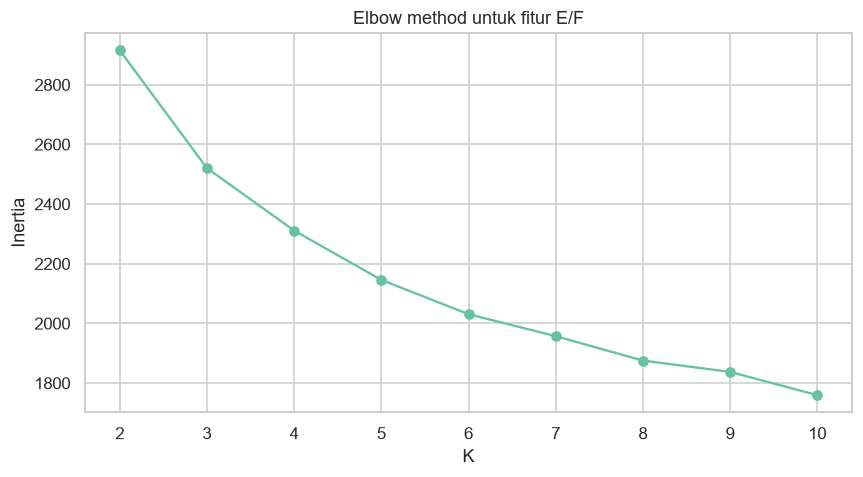

    K  Inertia
0   2  2915.20
1   3  2520.51
2   4  2311.18
3   5  2145.93
4   6  2030.93
5   7  1957.24
6   8  1875.46
7   9  1837.59
8  10  1759.55


In [19]:
cluster_features=["E.1","E.2","E.3",*[f"F.{i}" for i in [1,2,3,4,5,7,8]]]
cluster_scaler=StandardScaler()
Z=cluster_scaler.fit_transform(df[cluster_features])
elbow_rows=[]
for k in range(2,11):
    km=KMeans(n_clusters=k,random_state=SEED,n_init=20).fit(Z)
    elbow_rows.append({"K":k,"Inertia":km.inertia_})
elbow=pd.DataFrame(elbow_rows)
plt.figure(figsize=(8,4.5)); plt.plot(elbow["K"],elbow["Inertia"],marker="o"); plt.xticks(elbow["K"]); plt.xlabel("K"); plt.ylabel("Inertia"); plt.title("Elbow method untuk fitur E/F"); plt.tight_layout(); plt.show()
display(elbow.round(2))


In [20]:
FINAL_K=3
kmeans=KMeans(n_clusters=FINAL_K,random_state=SEED,n_init=20)
df["Cluster"]=kmeans.fit_predict(Z)
dbi=davies_bouldin_score(Z,df["Cluster"])
cluster_sizes=df["Cluster"].value_counts().sort_index()
print(f"K={FINAL_K}; Davies-Bouldin Index={dbi:.3f} (lebih rendah relatif lebih baik)")
display(pd.DataFrame({"n":cluster_sizes,"persentase":(cluster_sizes/len(df)*100).round(1)}))
cluster_profile=df.groupby("Cluster").agg(n=("No. Responden","size"),kepuasan_mean=("Kepuasan_F6","mean"),usia_mean=("A.2","mean"),pendapatan_median=("D.4","median"),D2_layak_mean=("D.2","mean"),E_mean=("E_perjalanan","mean"),beban_F_mean=("F_beban_waktu_stres","mean"))
for c in cluster_features: cluster_profile[c]=df.groupby("Cluster")[c].mean()
display(cluster_profile.round(2))


K=3; Davies-Bouldin Index=1.710 (lebih rendah relatif lebih baik)
           n  persentase
Cluster                 
0         96        25.0
1        165        43.0
2        123        32.0
           n  kepuasan_mean  usia_mean  pendapatan_median  D2_layak_mean  E_mean  beban_F_mean   E.1   E.2   E.3   F.1   F.2   F.3   F.4   F.5   F.7   F.8
Cluster                                                                                                                                                   
0         96           2.88      34.62          1900000.0           3.44    3.23          3.13  3.43  3.10  3.15  3.30  3.12  3.14  3.07  2.91  3.21  3.14
1        165           2.24      32.05          1800000.0           3.86    4.03          3.82  4.10  3.98  4.01  3.84  3.78  3.82  3.87  3.79  3.81  3.86
2        123           3.26      39.76          2500000.0           4.02    4.10          2.71  4.14  4.15  4.02  3.22  2.58  2.43  2.48  2.60  2.79  2.89


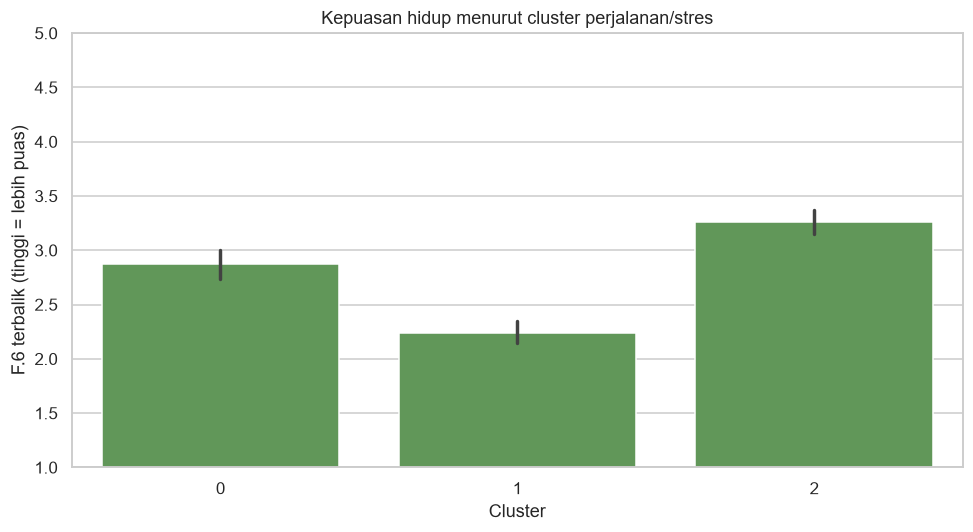

In [21]:
plt.figure(figsize=(9,5)); sns.barplot(data=df,x="Cluster",y="Kepuasan_F6",errorbar="ci",color="#59A14F"); plt.ylim(1,5); plt.title("Kepuasan hidup menurut cluster perjalanan/stres"); plt.ylabel("F.6 terbalik (tinggi = lebih puas)"); plt.tight_layout(); plt.show()


## Ringkasan temuan yang dihitung dari data

Kode berikut mengekstrak pola terkuat secara otomatis. Arah asosiasi dijelaskan dengan tanda Spearman; skor F.6 yang lebih besar berarti lebih puas. Untuk faktor kategori, gunakan tabel beserta `n` dan jangan menyamakan rerata kelompok kecil dengan kepastian populasi.

In [22]:
psych_rank = psych_corr.reindex(psych_corr.abs().sort_values(ascending=False).index)
strongest_psych = psych_rank.index[0]
strongest_econ = econ_corr.abs().idxmax()
best_cv = cv_results.iloc[0]
importance_rank = importance.sort_values("Penurunan R2 rata-rata", ascending=False)
age_summary = df.groupby("Kelompok usia", observed=True).agg(n=("No. Responden", "size"), mean=("Kepuasan_F6", "mean"))
best_age = age_summary["mean"].idxmax()
worst_age = age_summary["mean"].idxmin()
gender_means = df.groupby("Gender")["Kepuasan_F6"].mean()
status_means = df.groupby("Status").agg(n=("No. Responden", "size"), mean=("Kepuasan_F6", "mean"))
married_gender = df[df["A.3"].eq(1)].groupby("Gender").agg(n=("No. Responden", "size"), mean=("Kepuasan_F6", "mean"), burden=("F_beban_waktu_stres", "mean"))
print(f"1) Hubungan paling kuat antara satu butir perjalanan/tekanan dan target adalah {strongest_psych} (Spearman rho={psych_rank.iloc[0]:+.3f}); berikutnya: " + ", ".join(f"{i} ({v:+.3f})" for i,v in psych_rank.iloc[1:3].items()) + ". Rerata beban butir F berkorelasi rho=" + f"{df['F_beban_waktu_stres'].corr(df['Kepuasan_F6'], method='spearman'):+.3f}" + " dengan kepuasan (nilai negatif berarti beban lebih tinggi sejalan dengan kepuasan lebih rendah).")
print(f"   Model semua domain memiliki R2 CV {best_cv['R2 CV mean']:.3f} (SD antar-fold {best_cv['R2 CV sd']:.3f}); model perjalanan/stres saja R2 CV={cv_results.set_index('Domain model').loc['Perjalanan dan tekanan (E/F)', 'R2 CV mean']:.3f}, sedangkan ekonomi/perumahan/rumah tangga={cv_results.set_index('Domain model').loc['Ekonomi/perumahan/rumah tangga', 'R2 CV mean']:.3f} dan demografi={cv_results.set_index('Domain model').loc['Demografi', 'R2 CV mean']:.3f}. Pada holdout, R2={r2_score(y_test,y_pred):.3f}, MAE={mean_absolute_error(y_test,y_pred):.3f}; fitur permutation teratas: " + ", ".join(f"{r['Fitur']} (penurunan R2={r['Penurunan R2 rata-rata']:.3f})" for _,r in importance_rank.head(4).iterrows()) + ".")
print(f"2) Korelasi ekonomi/perumahan terkuat secara absolut adalah {strongest_econ} (rho={econ_corr[strongest_econ]:+.3f}), namun besar hubungannya lemah pada sampel ini. Rerata kepuasan tercile pendapatan rendah={income_table.iloc[0]['kepuasan_mean']:.2f}, menengah={income_table.iloc[1]['kepuasan_mean']:.2f}, tinggi={income_table.iloc[-1]['kepuasan_mean']:.2f}; rerata beban F masing-masing {income_table.iloc[0]['beban_mean']:.2f}, {income_table.iloc[1]['beban_mean']:.2f}, {income_table.iloc[-1]['beban_mean']:.2f}. Artinya pendapatan lebih tinggi di sini berkaitan dengan rerata beban yang lebih rendah, tetapi tidak tampak diikuti kenaikan kepuasan yang berarti.")
print(f"3) Kelompok usia dengan rerata kepuasan tertinggi adalah {best_age} (n={int(age_summary.loc[best_age,'n'])}, mean={age_summary.loc[best_age,'mean']:.2f}); terendah {worst_age} (n={int(age_summary.loc[worst_age,'n'])}, mean={age_summary.loc[worst_age,'mean']:.2f}). Rerata menurut gender: " + ", ".join(f"{idx}={val:.2f}" for idx,val in gender_means.items()) + ". Kelompok status/pekerjaan tercantum di tabel; kategori kecil tidak ditafsirkan jauh.")
if {'Laki-laki','Perempuan'}.issubset(married_gender.index):
    print(f"   Di antara yang menikah: perempuan n={int(married_gender.loc['Perempuan','n'])}, mean puas={married_gender.loc['Perempuan','mean']:.2f}, beban F={married_gender.loc['Perempuan','burden']:.2f}; laki-laki n={int(married_gender.loc['Laki-laki','n'])}, mean puas={married_gender.loc['Laki-laki','mean']:.2f}, beban F={married_gender.loc['Laki-laki','burden']:.2f}. Selisih deskriptif tidak berarti signifikan secara statistik.")
print(f"   Hubungan struktur rumah tangga dengan kepuasan lemah: korelasi C.1-C.4 terkuat secara absolut adalah {household_corr.abs().idxmax()} (rho={household_corr[household_corr.abs().idxmax()]:+.3f}).")
high_sat_cluster=cluster_profile['kepuasan_mean'].idxmax(); low_sat_cluster=cluster_profile['kepuasan_mean'].idxmin()
print(f"4) K-Means K=3, DBI={dbi:.3f}. Cluster dengan kepuasan rerata tertinggi adalah {high_sat_cluster} (mean={cluster_profile.loc[high_sat_cluster,'kepuasan_mean']:.2f}, beban F={cluster_profile.loc[high_sat_cluster,'beban_F_mean']:.2f}, E={cluster_profile.loc[high_sat_cluster,'E_mean']:.2f}; n={int(cluster_profile.loc[high_sat_cluster,'n'])}); terendah cluster {low_sat_cluster} (mean={cluster_profile.loc[low_sat_cluster,'kepuasan_mean']:.2f}, beban F={cluster_profile.loc[low_sat_cluster,'beban_F_mean']:.2f}, E={cluster_profile.loc[low_sat_cluster,'E_mean']:.2f}; n={int(cluster_profile.loc[low_sat_cluster,'n'])}).")
print("   Profil terukur per cluster:")
display(cluster_profile[["n","kepuasan_mean","usia_mean","pendapatan_median","D2_layak_mean","E_mean","beban_F_mean"]].round(2))

1) Hubungan paling kuat antara satu butir perjalanan/tekanan dan target adalah F.2 (Spearman rho=-0.567); berikutnya: F.3 (-0.511), F.8 (-0.502). Rerata beban butir F berkorelasi rho=-0.634 dengan kepuasan (nilai negatif berarti beban lebih tinggi sejalan dengan kepuasan lebih rendah).
   Model semua domain memiliki R2 CV 0.472 (SD antar-fold 0.070); model perjalanan/stres saja R2 CV=0.467, sedangkan ekonomi/perumahan/rumah tangga=-0.028 dan demografi=0.003. Pada holdout, R2=0.492, MAE=0.466; fitur permutation teratas: F.2 (penurunan R2=0.226), F.8 (penurunan R2=0.136), F.3 (penurunan R2=0.111), A.4 (penurunan R2=0.032).
2) Korelasi ekonomi/perumahan terkuat secara absolut adalah D.3 (rho=-0.091), namun besar hubungannya lemah pada sampel ini. Rerata kepuasan tercile pendapatan rendah=2.69, menengah=2.75, tinggi=2.74; rerata beban F masing-masing 3.37, 3.32, 3.15. Artinya pendapatan lebih tinggi di sini berkaitan dengan rerata beban yang lebih rendah, tetapi tidak tampak diikuti kenaik

## Kesimpulan, rekomendasi pembacaan, dan keterbatasan

Gunakan hasil di atas untuk menjawab pertanyaan yang dipilih: (a) faktor E/F dengan korelasi terkuat; (b) domain dengan prediksi CV terbaik dan permutation importance terbesar; (c) pola kondisi rumah/ekonomi; (d) variasi demografi/rumah tangga; dan (e) perbedaan kepuasan antarkluster. Hubungan bivariat, model multivariat, dan hasil cluster menjawab pertanyaan yang berbeda?jangan menyebutnya sebagai ?penentu? kausal.

- Sampel hanya 384 responden yang tersedia; keterwakilan populasi tidak diketahui.
- F.6 adalah satu butir negatif; skornya dibalik untuk arah interpretasi, tetapi reliabilitas konstruk tidak dapat diuji dari satu butir. Kategori `Kepuasan Hidup` tidak memiliki pemetaan sumber yang jelas ke F.6.
- Likert dianggap numerik. Linear regression memodelkan skor bounded 1?5 secara sederhana; R? dapat rendah dan koefisien tidak ditafsirkan sebagai sebab-akibat.
- F.1?F.5/F.7/F.8 berdekatan secara konsep dengan F.6, sehingga prediksi dapat mengandung tumpang tindih konseptual/common-method bias. Kinerja CV dan holdout bergantung pada pembagian sampel.
- Pilihan kategori agama/pendidikan/status tertentu jarang; perbandingan subkelompok kecil tidak stabil.
- K-Means bersifat eksploratif dan DBI bukan validasi eksternal. K=3 mengikuti permintaan, walau elbow mungkin tidak memiliki titik patah tegas.
- Pendapatan IDR/USD dua representasi mata uang; model memakai log pendapatan IDR. Tidak tersedia biaya hidup, jam kerja aktual, jarak perjalanan dalam satuan, atau desain longitudinal untuk menguji kompensasi dan sebab-akibat.